PROJECT ROOT: /Users/am/Documents/ADU/wifi-localization-research
Training file exists: True
Test file exists: True

EXPERIMENT SETTINGS
Random state: 42
Augmentation seeds: [142, 242]
Evaluation seeds: [42, 43, 44, 45, 46]
Maximum epochs: 300
Early-stopping patience: 15

DATASET
Official training rows: 19937
Official validation/final-test rows: 1111
Wi-Fi features: 520

RSSI PREPROCESSING
Training observed entries: 358763
Training missing percentage: 96.54 %
Mean observed APs/fingerprint: 17.99

ORIGINAL PROJECT SPLIT
Training: 15949
Development: 3988

REVIEWER-CONTROL TRAINING SPLIT
Model-fit fingerprints: 14354
Fixed early-stop fingerprints: 1595
Development fingerprints: 3988
Final-test fingerprints: 1111

Feature scaler saved.
Coordinate scaler saved.

TRAINING REGIME SIZES
Clean           samples = 14354
Repeated Clean  samples = 43062
AP Dropout      samples = 43062
Combined        samples = 43062

TRAINING REGIME: Clean
Classifier best fixed-stop accuracy: 0.9925
Regressor best 

,Training_Regime,Training_Samples,Best_Stop_Classification_Accuracy,Best_Stop_Localization_Error,Training_Time_Seconds
0,Clean,14354,0.9925,5.8875,5.1200
1,Repeated Clean,43062,0.9944,5.6617,10.7034
2,AP Dropout,43062,0.9937,6.3221,18.0682
3,Combined,43062,0.9918,6.0782,14.9823



DEVELOPMENT CONTROL RESULTS


,Dataset,Condition,Training_Regime,Accuracy,Accuracy_SD,Macro_F1,Mean_Localization_Error,Localization_Error_SD
0,Development,50% AP Loss,AP Dropout,0.8993,0.0063,0.8964,11.4854,0.1343
1,Development,50% AP Loss,Clean,0.8298,0.0066,0.8233,21.0343,0.2185
2,Development,50% AP Loss,Combined,0.8810,0.0078,0.8791,11.5309,0.1285
3,Development,50% AP Loss,Repeated Clean,0.8175,0.0065,0.8122,21.4684,0.2368
4,Development,50% AP Loss + sigma=10,AP Dropout,0.8714,0.0059,0.8675,12.8266,0.2056
5,Development,50% AP Loss + sigma=10,Clean,0.8056,0.0029,0.7989,22.6324,0.1766
6,Development,50% AP Loss + sigma=10,Combined,0.8600,0.0056,0.8578,12.6832,0.1444
7,Development,50% AP Loss + sigma=10,Repeated Clean,0.7952,0.0049,0.7899,23.0102,0.2383
8,Development,Clean,AP Dropout,0.9932,NaN,0.9929,6.2466,NaN
9,Development,Clean,Clean,0.9932,NaN,0.9925,5.8389,NaN



FINAL-TEST POST-HOC CONTROL RESULTS


,Dataset,Condition,Training_Regime,Accuracy,Accuracy_SD,Macro_F1,Mean_Localization_Error,Localization_Error_SD
0,Final Test — Post-hoc Reviewer Control,50% AP Loss,AP Dropout,0.7604,0.0105,0.7449,15.2523,0.3844
1,Final Test — Post-hoc Reviewer Control,50% AP Loss,Clean,0.7204,0.0072,0.6979,29.6482,0.3424
2,Final Test — Post-hoc Reviewer Control,50% AP Loss,Combined,0.7577,0.0071,0.7469,15.0439,0.3807
3,Final Test — Post-hoc Reviewer Control,50% AP Loss,Repeated Clean,0.7098,0.0105,0.6871,31.2787,0.4735
4,Final Test — Post-hoc Reviewer Control,50% AP Loss + sigma=10,AP Dropout,0.7343,0.0065,0.7173,16.5052,0.4167
5,Final Test — Post-hoc Reviewer Control,50% AP Loss + sigma=10,Clean,0.7003,0.0142,0.6808,31.1357,0.3965
6,Final Test — Post-hoc Reviewer Control,50% AP Loss + sigma=10,Combined,0.7377,0.0071,0.7256,16.3305,0.3967
7,Final Test — Post-hoc Reviewer Control,50% AP Loss + sigma=10,Repeated Clean,0.6857,0.0121,0.6636,32.7550,0.6224
8,Final Test — Post-hoc Reviewer Control,Clean,AP Dropout,0.8974,NaN,0.8793,10.7932,NaN
9,Final Test — Post-hoc Reviewer Control,Clean,Clean,0.9136,NaN,0.8965,13.2954,NaN



REVIEWER QUESTION — EQUAL-VOLUME CONTROL

SEVERE CONDITION:
50% AP loss + RSSI Gaussian noise sigma=10 dB

CLASSIFICATION
Repeated-Clean accuracy: 0.6857
AP-dropout accuracy: 0.7343
AP-dropout improvement over equal-volume clean: 0.0486
Improvement in percentage points: 4.86

LOCALIZATION
Repeated-Clean mean error: 32.755
Combined-training mean error: 16.3305
Error reduction vs equal-volume clean: 16.4245


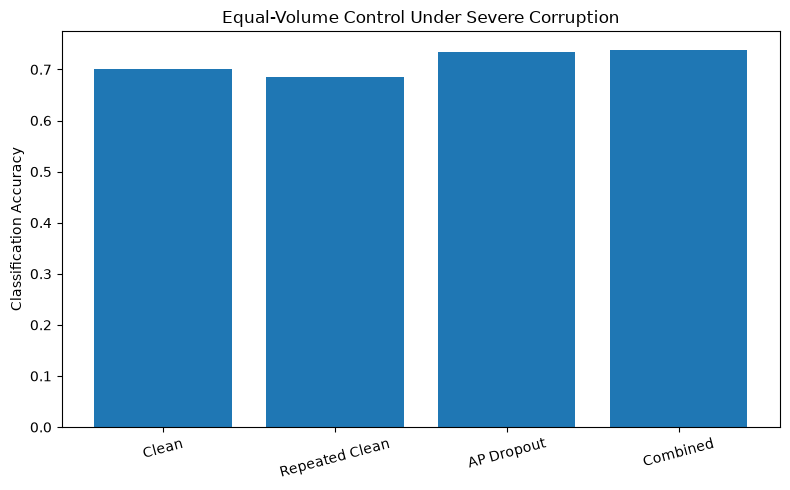

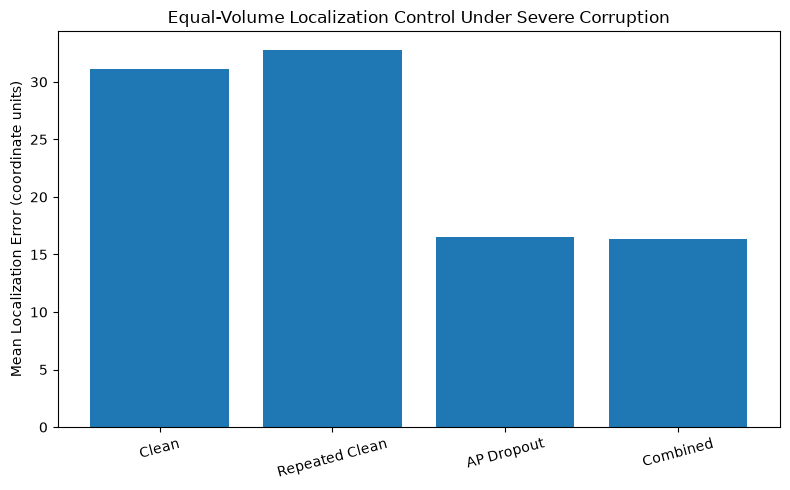


NOTEBOOK 11 COMPLETED SUCCESSFULLY

Saved models:
- ap_dropout_classifier.joblib
- ap_dropout_regressor.joblib
- clean_classifier.joblib
- clean_regressor.joblib
- combined_classifier.joblib
- combined_regressor.joblib
- repeated_clean_classifier.joblib
- repeated_clean_regressor.joblib
- review_coordinate_scaler.joblib
- review_feature_scaler.joblib

Saved CSV files:
- 11_ap_dropout_classifier_history.csv
- 11_ap_dropout_regressor_history.csv
- 11_clean_classifier_history.csv
- 11_clean_regressor_history.csv
- 11_combined_classifier_history.csv
- 11_combined_regressor_history.csv
- 11_equal_volume_development_detailed.csv
- 11_equal_volume_development_summary.csv
- 11_equal_volume_final_test_detailed.csv
- 11_equal_volume_final_test_summary.csv
- 11_equal_volume_metadata.json
- 11_repeated_clean_classifier_history.csv
- 11_repeated_clean_regressor_history.csv
- 11_reviewer_control_effects.csv
- 11_training_summary.csv

Saved figures:
- 11_equal_volume_severe_classification.png
- 11_e

In [1]:
# ============================================================
# NOTEBOOK 11
# Equal-Volume Control for Reviewer Revision
#
# Purpose:
#   1. Control for the ~3x training-volume confound.
#   2. Use a leakage-resistant fixed early-stopping split.
#   3. Compare:
#        - Clean
#        - Repeated Clean
#        - AP Dropout
#        - Combined AP Dropout + RSSI Noise
#   4. Evaluate classification and coordinate localization.
#
# IMPORTANT:
#   This is a reviewer-requested post-hoc control experiment.
#   It does NOT replace the original frozen experiment.
# ============================================================


# ------------------------------------------------------------
# Step 1 — Imports
# ------------------------------------------------------------

from pathlib import Path
import copy
import json
import time
import warnings

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# Step 2 — Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "Documents" / "ADU" / "wifi-localization-research"

DATA_RAW = PROJECT_ROOT / "data" / "raw"

TRAIN_FILE = DATA_RAW / "trainingData.csv"
TEST_FILE = DATA_RAW / "validationData.csv"

RESULTS_CSV = PROJECT_ROOT / "results" / "csv"
RESULTS_FIG = PROJECT_ROOT / "results" / "figures"
MODEL_DIR = PROJECT_ROOT / "models" / "11_equal_volume_control"

RESULTS_CSV.mkdir(parents=True, exist_ok=True)
RESULTS_FIG.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT:", PROJECT_ROOT)
print("Training file exists:", TRAIN_FILE.exists())
print("Test file exists:", TEST_FILE.exists())

assert TRAIN_FILE.exists(), f"Missing: {TRAIN_FILE}"
assert TEST_FILE.exists(), f"Missing: {TEST_FILE}"


# ------------------------------------------------------------
# Step 3 — Reproducibility constants
# ------------------------------------------------------------

RANDOM_STATE = 42

# Original project split
DEV_SIZE = 0.20

# New explicit early-stopping split
EARLY_STOP_SIZE = 0.10

MISSING_ORIGINAL = 100
MISSING_RSSI = -110.0

MIN_OBSERVED_RSSI = -104.0
MAX_OBSERVED_RSSI = 0.0

AP_LEVELS = [0.10, 0.20, 0.30, 0.40, 0.50]
NOISE_LEVELS = [2.0, 5.0, 10.0]

# Same two augmentation-copy concept used in the original robust training.
AUGMENTATION_SEEDS = [142, 242]

# Original corruption seeds for direct comparison.
EVAL_SEEDS = [42, 43, 44, 45, 46]

MAX_EPOCHS = 300
PATIENCE = 15

# Explicit MLP hyperparameters.
MLP_PARAMS = {
    "hidden_layer_sizes": (128, 64),
    "activation": "relu",
    "solver": "adam",
    "alpha": 0.0001,
    "batch_size": 200,
    "learning_rate": "constant",
    "learning_rate_init": 0.001,
    "power_t": 0.5,
    "shuffle": True,
    "random_state": RANDOM_STATE,
    "tol": 1e-4,
    "momentum": 0.9,
    "nesterovs_momentum": True,
    "early_stopping": False,  # handled manually below
    "validation_fraction": 0.1,
    "beta_1": 0.9,
    "beta_2": 0.999,
    "epsilon": 1e-8,
    "n_iter_no_change": PATIENCE,
    "max_iter": 1
}

print("\nEXPERIMENT SETTINGS")
print("Random state:", RANDOM_STATE)
print("Augmentation seeds:", AUGMENTATION_SEEDS)
print("Evaluation seeds:", EVAL_SEEDS)
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)


# ------------------------------------------------------------
# Step 4 — Load raw UJIIndoorLoc files
# ------------------------------------------------------------

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

wifi_cols = [c for c in train_df.columns if c.upper().startswith("WAP")]

print("\nDATASET")
print("Official training rows:", len(train_df))
print("Official validation/final-test rows:", len(test_df))
print("Wi-Fi features:", len(wifi_cols))

assert len(train_df) == 19937
assert len(test_df) == 1111
assert len(wifi_cols) == 520


# ------------------------------------------------------------
# Step 5 — Build classification and regression targets
# ------------------------------------------------------------

# Joint building-floor label.
def make_class_labels(df):
    return (
        df["BUILDINGID"].astype(int).astype(str)
        + "_"
        + df["FLOOR"].astype(int).astype(str)
    ).to_numpy()


y_all_cls = make_class_labels(train_df)
y_test_cls = make_class_labels(test_df)

# Coordinate targets.
COORD_COLS = ["LONGITUDE", "LATITUDE"]

y_all_reg = train_df[COORD_COLS].to_numpy(dtype=np.float64)
y_test_reg = test_df[COORD_COLS].to_numpy(dtype=np.float64)


# ------------------------------------------------------------
# Step 6 — Prepare raw RSSI matrices and observation masks
# ------------------------------------------------------------

X_all_original = train_df[wifi_cols].to_numpy(dtype=np.float64)
X_test_original = test_df[wifi_cols].to_numpy(dtype=np.float64)

mask_all = X_all_original != MISSING_ORIGINAL
mask_test = X_test_original != MISSING_ORIGINAL

X_all_raw = X_all_original.copy()
X_test_raw = X_test_original.copy()

X_all_raw[~mask_all] = MISSING_RSSI
X_test_raw[~mask_test] = MISSING_RSSI

print("\nRSSI PREPROCESSING")
print("Training observed entries:", int(mask_all.sum()))
print("Training missing percentage:",
      round(100 * (1 - mask_all.mean()), 2), "%")
print("Mean observed APs/fingerprint:",
      round(mask_all.sum(axis=1).mean(), 2))


# ------------------------------------------------------------
# Step 7 — Recreate original 80/20 train-development split
# ------------------------------------------------------------

all_indices = np.arange(len(train_df))

train_indices, dev_indices = train_test_split(
    all_indices,
    test_size=DEV_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_all_cls
)

print("\nORIGINAL PROJECT SPLIT")
print("Training:", len(train_indices))
print("Development:", len(dev_indices))

assert len(train_indices) == 15949
assert len(dev_indices) == 3988


# ------------------------------------------------------------
# Step 8 — Create fixed early-stopping split BEFORE augmentation
# ------------------------------------------------------------

fit_indices, stop_indices = train_test_split(
    train_indices,
    test_size=EARLY_STOP_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_all_cls[train_indices]
)

print("\nREVIEWER-CONTROL TRAINING SPLIT")
print("Model-fit fingerprints:", len(fit_indices))
print("Fixed early-stop fingerprints:", len(stop_indices))
print("Development fingerprints:", len(dev_indices))
print("Final-test fingerprints:", len(test_df))

# Raw features.
X_fit_raw = X_all_raw[fit_indices]
X_stop_raw = X_all_raw[stop_indices]
X_dev_raw = X_all_raw[dev_indices]

mask_fit = mask_all[fit_indices]
mask_stop = mask_all[stop_indices]
mask_dev = mask_all[dev_indices]

# Classification targets.
y_fit_cls = y_all_cls[fit_indices]
y_stop_cls = y_all_cls[stop_indices]
y_dev_cls = y_all_cls[dev_indices]

# Regression targets.
y_fit_reg = y_all_reg[fit_indices]
y_stop_reg = y_all_reg[stop_indices]
y_dev_reg = y_all_reg[dev_indices]


# ------------------------------------------------------------
# Step 9 — Fit feature scaler ONLY on model-fit fingerprints
# ------------------------------------------------------------

feature_scaler = MinMaxScaler()

X_fit = feature_scaler.fit_transform(X_fit_raw)
X_stop = feature_scaler.transform(X_stop_raw)
X_dev = feature_scaler.transform(X_dev_raw)
X_test = feature_scaler.transform(X_test_raw)

joblib.dump(
    feature_scaler,
    MODEL_DIR / "review_feature_scaler.joblib"
)

print("\nFeature scaler saved.")


# ------------------------------------------------------------
# Step 10 — Fit coordinate scaler only on model-fit targets
# ------------------------------------------------------------

coordinate_scaler = StandardScaler()

y_fit_reg_scaled = coordinate_scaler.fit_transform(y_fit_reg)
y_stop_reg_scaled = coordinate_scaler.transform(y_stop_reg)

joblib.dump(
    coordinate_scaler,
    MODEL_DIR / "review_coordinate_scaler.joblib"
)

print("Coordinate scaler saved.")


# ------------------------------------------------------------
# Step 11 — Corruption functions
# ------------------------------------------------------------

def apply_ap_dropout(
    X_raw,
    observed_mask,
    rng,
    fixed_fraction=None
):
    """
    Drop originally observed APs only.

    If fixed_fraction is None, sample an AP-loss level
    independently for each fingerprint.
    """

    X_corrupt = X_raw.copy()
    surviving_mask = observed_mask.copy()

    n_samples = X_raw.shape[0]

    for i in range(n_samples):

        observed = np.flatnonzero(observed_mask[i])

        if len(observed) == 0:
            continue

        if fixed_fraction is None:
            p = float(rng.choice(AP_LEVELS))
        else:
            p = float(fixed_fraction)

        if p <= 0:
            continue

        n_drop = int(np.floor(p * len(observed)))

        # Preserve the original project's nonzero-loss behavior:
        # at least one observed AP is removed.
        n_drop = max(1, n_drop)
        n_drop = min(n_drop, len(observed))

        drop_idx = rng.choice(
            observed,
            size=n_drop,
            replace=False
        )

        X_corrupt[i, drop_idx] = MISSING_RSSI
        surviving_mask[i, drop_idx] = False

    return X_corrupt, surviving_mask


def apply_rssi_noise(
    X_raw,
    surviving_mask,
    rng,
    fixed_sigma=None
):
    """
    Add Gaussian noise only to surviving observed APs.
    Missing/dropped APs remain exactly -110 dBm.
    """

    X_corrupt = X_raw.copy()

    n_samples = X_raw.shape[0]

    for i in range(n_samples):

        observed = np.flatnonzero(surviving_mask[i])

        if len(observed) == 0:
            continue

        if fixed_sigma is None:
            sigma = float(rng.choice(NOISE_LEVELS))
        else:
            sigma = float(fixed_sigma)

        if sigma <= 0:
            continue

        noise = rng.normal(
            loc=0.0,
            scale=sigma,
            size=len(observed)
        )

        X_corrupt[i, observed] += noise

        X_corrupt[i, observed] = np.clip(
            X_corrupt[i, observed],
            MIN_OBSERVED_RSSI,
            MAX_OBSERVED_RSSI
        )

    X_corrupt[~surviving_mask] = MISSING_RSSI

    return X_corrupt


def create_augmented_copy(
    X_raw,
    observed_mask,
    mode,
    seed
):
    rng = np.random.default_rng(seed)

    if mode == "ap_dropout":

        X_aug, _ = apply_ap_dropout(
            X_raw,
            observed_mask,
            rng,
            fixed_fraction=None
        )

        return X_aug

    elif mode == "combined":

        X_aug, surviving = apply_ap_dropout(
            X_raw,
            observed_mask,
            rng,
            fixed_fraction=None
        )

        X_aug = apply_rssi_noise(
            X_aug,
            surviving,
            rng,
            fixed_sigma=None
        )

        return X_aug

    else:
        raise ValueError(f"Unknown augmentation mode: {mode}")


# ------------------------------------------------------------
# Step 12 — Build equal-volume reviewer-control regimes
# ------------------------------------------------------------

def build_training_regime(mode):

    # Clean baseline = one copy only.
    if mode == "Clean":

        return (
            X_fit_raw.copy(),
            y_fit_cls.copy(),
            y_fit_reg.copy()
        )

    # Equal-volume clean control:
    # clean + clean + clean
    if mode == "Repeated Clean":

        X = np.concatenate(
            [X_fit_raw, X_fit_raw, X_fit_raw],
            axis=0
        )

        yc = np.concatenate(
            [y_fit_cls, y_fit_cls, y_fit_cls],
            axis=0
        )

        yr = np.concatenate(
            [y_fit_reg, y_fit_reg, y_fit_reg],
            axis=0
        )

        return X, yc, yr

    if mode == "AP Dropout":

        copies = [X_fit_raw]

        for seed in AUGMENTATION_SEEDS:
            copies.append(
                create_augmented_copy(
                    X_fit_raw,
                    mask_fit,
                    mode="ap_dropout",
                    seed=seed
                )
            )

        X = np.concatenate(copies, axis=0)

        yc = np.tile(
            y_fit_cls,
            len(copies)
        )

        yr = np.tile(
            y_fit_reg,
            (len(copies), 1)
        )

        return X, yc, yr

    if mode == "Combined":

        copies = [X_fit_raw]

        for seed in AUGMENTATION_SEEDS:
            copies.append(
                create_augmented_copy(
                    X_fit_raw,
                    mask_fit,
                    mode="combined",
                    seed=seed
                )
            )

        X = np.concatenate(copies, axis=0)

        yc = np.tile(
            y_fit_cls,
            len(copies)
        )

        yr = np.tile(
            y_fit_reg,
            (len(copies), 1)
        )

        return X, yc, yr

    raise ValueError(mode)


REGIMES = [
    "Clean",
    "Repeated Clean",
    "AP Dropout",
    "Combined"
]

print("\nTRAINING REGIME SIZES")

for regime in REGIMES:

    X_tmp, yc_tmp, yr_tmp = build_training_regime(regime)

    print(
        f"{regime:15s}",
        "samples =",
        len(X_tmp)
    )


# ------------------------------------------------------------
# Step 13 — Manual explicit early stopping: classification
# ------------------------------------------------------------

def train_classifier_explicit_early_stop(
    X_train,
    y_train,
    X_val,
    y_val,
    random_state=42
):

    model = MLPClassifier(**MLP_PARAMS)

    classes = np.unique(y_train)

    best_model = None
    best_score = -np.inf

    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):

        if epoch == 1:
            model.partial_fit(
                X_train,
                y_train,
                classes=classes
            )
        else:
            model.partial_fit(
                X_train,
                y_train
            )

        pred = model.predict(X_val)

        score = accuracy_score(
            y_val,
            pred
        )

        history.append(
            {
                "epoch": epoch,
                "validation_accuracy": score
            }
        )

        if score > best_score + 1e-5:

            best_score = score
            best_model = copy.deepcopy(model)
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

    return (
        best_model,
        pd.DataFrame(history),
        best_score
    )


# ------------------------------------------------------------
# Step 14 — Manual explicit early stopping: regression
# ------------------------------------------------------------

def mean_euclidean_error(
    y_true,
    y_pred
):
    return np.mean(
        np.linalg.norm(
            y_pred - y_true,
            axis=1
        )
    )


def train_regressor_explicit_early_stop(
    X_train,
    y_train_scaled,
    X_val,
    y_val_unscaled,
    coordinate_scaler,
    random_state=42
):

    model = MLPRegressor(**MLP_PARAMS)

    best_model = None
    best_error = np.inf

    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):

        model.partial_fit(
            X_train,
            y_train_scaled
        )

        pred_scaled = model.predict(X_val)

        pred = coordinate_scaler.inverse_transform(
            pred_scaled
        )

        error = mean_euclidean_error(
            y_val_unscaled,
            pred
        )

        history.append(
            {
                "epoch": epoch,
                "validation_mean_error": error
            }
        )

        if error < best_error - 1e-5:

            best_error = error
            best_model = copy.deepcopy(model)
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

    return (
        best_model,
        pd.DataFrame(history),
        best_error
    )


# ------------------------------------------------------------
# Step 15 — Train all four reviewer-control regimes
# ------------------------------------------------------------

classifier_models = {}
regressor_models = {}

training_summary = []

for regime in REGIMES:

    print("\n" + "=" * 70)
    print("TRAINING REGIME:", regime)
    print("=" * 70)

    start_time = time.time()

    X_regime_raw, yc_regime, yr_regime = build_training_regime(
        regime
    )

    # IMPORTANT:
    # corruption occurred in raw dBm space.
    # Scaling happens only now.
    X_regime = feature_scaler.transform(
        X_regime_raw
    )

    yr_regime_scaled = coordinate_scaler.transform(
        yr_regime
    )

    # ----------------------------
    # Classification
    # ----------------------------

    clf, clf_history, best_acc = (
        train_classifier_explicit_early_stop(
            X_regime,
            yc_regime,
            X_stop,
            y_stop_cls
        )
    )

    classifier_models[regime] = clf

    joblib.dump(
        clf,
        MODEL_DIR
        / f"{regime.lower().replace(' ', '_')}_classifier.joblib"
    )

    clf_history.to_csv(
        RESULTS_CSV
        / f"11_{regime.lower().replace(' ', '_')}_classifier_history.csv",
        index=False
    )

    print(
        "Classifier best fixed-stop accuracy:",
        round(best_acc, 4)
    )

    # ----------------------------
    # Regression
    # ----------------------------

    reg, reg_history, best_error = (
        train_regressor_explicit_early_stop(
            X_regime,
            yr_regime_scaled,
            X_stop,
            y_stop_reg,
            coordinate_scaler
        )
    )

    regressor_models[regime] = reg

    joblib.dump(
        reg,
        MODEL_DIR
        / f"{regime.lower().replace(' ', '_')}_regressor.joblib"
    )

    reg_history.to_csv(
        RESULTS_CSV
        / f"11_{regime.lower().replace(' ', '_')}_regressor_history.csv",
        index=False
    )

    elapsed = time.time() - start_time

    print(
        "Regressor best fixed-stop error:",
        round(best_error, 4)
    )

    print(
        "Training time:",
        round(elapsed, 1),
        "seconds"
    )

    training_summary.append(
        {
            "Training_Regime": regime,
            "Training_Samples": len(X_regime),
            "Best_Stop_Classification_Accuracy": best_acc,
            "Best_Stop_Localization_Error": best_error,
            "Training_Time_Seconds": elapsed
        }
    )


training_summary_df = pd.DataFrame(
    training_summary
)

training_summary_df.to_csv(
    RESULTS_CSV
    / "11_training_summary.csv",
    index=False
)

print("\nTRAINING SUMMARY")
display(
    training_summary_df.round(4)
)


# ------------------------------------------------------------
# Step 16 — Evaluation helper
# ------------------------------------------------------------

def evaluate_condition(
    X_raw,
    observed_mask,
    y_cls,
    y_reg,
    ap_loss,
    sigma,
    seed
):

    rng = np.random.default_rng(seed)

    X_corr = X_raw.copy()
    surviving = observed_mask.copy()

    if ap_loss > 0:

        X_corr, surviving = apply_ap_dropout(
            X_corr,
            surviving,
            rng,
            fixed_fraction=ap_loss
        )

    if sigma > 0:

        X_corr = apply_rssi_noise(
            X_corr,
            surviving,
            rng,
            fixed_sigma=sigma
        )

    X_scaled = feature_scaler.transform(
        X_corr
    )

    rows = []

    for regime in REGIMES:

        # Classification.
        clf = classifier_models[regime]

        pred_cls = clf.predict(
            X_scaled
        )

        acc = accuracy_score(
            y_cls,
            pred_cls
        )

        f1 = f1_score(
            y_cls,
            pred_cls,
            average="macro"
        )

        # Regression.
        reg = regressor_models[regime]

        pred_reg_scaled = reg.predict(
            X_scaled
        )

        pred_reg = coordinate_scaler.inverse_transform(
            pred_reg_scaled
        )

        mean_err = mean_euclidean_error(
            y_reg,
            pred_reg
        )

        rows.append(
            {
                "Training_Regime": regime,
                "AP_Loss": ap_loss,
                "RSSI_Sigma": sigma,
                "Seed": seed,
                "Accuracy": acc,
                "Macro_F1": f1,
                "Mean_Localization_Error": mean_err
            }
        )

    return rows


# ------------------------------------------------------------
# Step 17 — Evaluate development set
#
# This remains the correct place for interpretation/model
# comparison because the final test was already examined
# in the original study.
# ------------------------------------------------------------

KEY_CONDITIONS = [
    ("Clean", 0.0, 0.0),
    ("50% AP Loss", 0.50, 0.0),
    ("RSSI sigma=10", 0.0, 10.0),
    ("50% AP Loss + sigma=10", 0.50, 10.0)
]

dev_rows = []

for condition_name, p, sigma in KEY_CONDITIONS:

    seeds = [42] if (p == 0 and sigma == 0) else EVAL_SEEDS

    for seed in seeds:

        rows = evaluate_condition(
            X_dev_raw,
            mask_dev,
            y_dev_cls,
            y_dev_reg,
            p,
            sigma,
            seed
        )

        for row in rows:

            row["Dataset"] = "Development"
            row["Condition"] = condition_name

        dev_rows.extend(rows)


dev_detailed = pd.DataFrame(
    dev_rows
)

dev_summary = (
    dev_detailed
    .groupby(
        [
            "Dataset",
            "Condition",
            "Training_Regime"
        ],
        as_index=False
    )
    .agg(
        Accuracy=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        Macro_F1=("Macro_F1", "mean"),
        Mean_Localization_Error=(
            "Mean_Localization_Error",
            "mean"
        ),
        Localization_Error_SD=(
            "Mean_Localization_Error",
            "std"
        )
    )
)

dev_detailed.to_csv(
    RESULTS_CSV
    / "11_equal_volume_development_detailed.csv",
    index=False
)

dev_summary.to_csv(
    RESULTS_CSV
    / "11_equal_volume_development_summary.csv",
    index=False
)

print("\nDEVELOPMENT CONTROL RESULTS")
display(
    dev_summary.round(4)
)


# ------------------------------------------------------------
# Step 18 — Post-hoc final-test control
#
# IMPORTANT:
# These are reviewer-requested post-hoc controls.
# They must NOT be described as originally pre-specified.
# ------------------------------------------------------------

test_rows = []

for condition_name, p, sigma in KEY_CONDITIONS:

    seeds = [42] if (p == 0 and sigma == 0) else EVAL_SEEDS

    for seed in seeds:

        rows = evaluate_condition(
            X_test_raw,
            mask_test,
            y_test_cls,
            y_test_reg,
            p,
            sigma,
            seed
        )

        for row in rows:

            row["Dataset"] = "Final Test — Post-hoc Reviewer Control"
            row["Condition"] = condition_name

        test_rows.extend(rows)


test_detailed = pd.DataFrame(
    test_rows
)

test_summary = (
    test_detailed
    .groupby(
        [
            "Dataset",
            "Condition",
            "Training_Regime"
        ],
        as_index=False
    )
    .agg(
        Accuracy=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        Macro_F1=("Macro_F1", "mean"),
        Mean_Localization_Error=(
            "Mean_Localization_Error",
            "mean"
        ),
        Localization_Error_SD=(
            "Mean_Localization_Error",
            "std"
        )
    )
)

test_detailed.to_csv(
    RESULTS_CSV
    / "11_equal_volume_final_test_detailed.csv",
    index=False
)

test_summary.to_csv(
    RESULTS_CSV
    / "11_equal_volume_final_test_summary.csv",
    index=False
)

print("\nFINAL-TEST POST-HOC CONTROL RESULTS")
display(
    test_summary.round(4)
)


# ------------------------------------------------------------
# Step 19 — Direct reviewer comparison
#
# Most important:
# Repeated Clean vs AP Dropout for classification.
# Repeated Clean vs Combined for localization.
# ------------------------------------------------------------

SEVERE_CONDITION = "50% AP Loss + sigma=10"

severe_test = test_summary[
    test_summary["Condition"] == SEVERE_CONDITION
].copy()

def get_value(
    df,
    regime,
    column
):
    return float(
        df.loc[
            df["Training_Regime"] == regime,
            column
        ].iloc[0]
    )


repeated_acc = get_value(
    severe_test,
    "Repeated Clean",
    "Accuracy"
)

dropout_acc = get_value(
    severe_test,
    "AP Dropout",
    "Accuracy"
)

repeated_error = get_value(
    severe_test,
    "Repeated Clean",
    "Mean_Localization_Error"
)

combined_error = get_value(
    severe_test,
    "Combined",
    "Mean_Localization_Error"
)

classification_gain = (
    dropout_acc - repeated_acc
)

localization_reduction = (
    repeated_error - combined_error
)

reviewer_answer = pd.DataFrame(
    [
        {
            "Comparison":
                "AP Dropout vs Equal-Volume Repeated Clean",
            "Task":
                "Classification",
            "Severe_Control_Effect":
                classification_gain
        },
        {
            "Comparison":
                "Combined vs Equal-Volume Repeated Clean",
            "Task":
                "Localization",
            "Severe_Control_Effect":
                localization_reduction
        }
    ]
)

reviewer_answer.to_csv(
    RESULTS_CSV
    / "11_reviewer_control_effects.csv",
    index=False
)

print("\n" + "=" * 80)
print("REVIEWER QUESTION — EQUAL-VOLUME CONTROL")
print("=" * 80)

print("\nSEVERE CONDITION:")
print("50% AP loss + RSSI Gaussian noise sigma=10 dB")

print("\nCLASSIFICATION")
print(
    "Repeated-Clean accuracy:",
    round(repeated_acc, 4)
)
print(
    "AP-dropout accuracy:",
    round(dropout_acc, 4)
)
print(
    "AP-dropout improvement over equal-volume clean:",
    round(classification_gain, 4)
)
print(
    "Improvement in percentage points:",
    round(classification_gain * 100, 2)
)

print("\nLOCALIZATION")
print(
    "Repeated-Clean mean error:",
    round(repeated_error, 4)
)
print(
    "Combined-training mean error:",
    round(combined_error, 4)
)
print(
    "Error reduction vs equal-volume clean:",
    round(localization_reduction, 4)
)


# ------------------------------------------------------------
# Step 20 — Reviewer-control figure
# ------------------------------------------------------------

plot_df = severe_test.set_index(
    "Training_Regime"
).loc[
    [
        "Clean",
        "Repeated Clean",
        "AP Dropout",
        "Combined"
    ]
]

plt.figure(figsize=(8, 5))

plt.bar(
    plot_df.index,
    plot_df["Accuracy"]
)

plt.ylabel("Classification Accuracy")
plt.title(
    "Equal-Volume Control Under Severe Corruption"
)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    RESULTS_FIG
    / "11_equal_volume_severe_classification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 5))

plt.bar(
    plot_df.index,
    plot_df["Mean_Localization_Error"]
)

plt.ylabel(
    "Mean Localization Error (coordinate units)"
)

plt.title(
    "Equal-Volume Localization Control Under Severe Corruption"
)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    RESULTS_FIG
    / "11_equal_volume_severe_localization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Step 21 — Save experiment metadata
# ------------------------------------------------------------

metadata = {
    "experiment":
        "Reviewer-requested equal-volume augmentation control",
    "post_hoc":
        True,
    "random_state":
        RANDOM_STATE,
    "original_training_samples":
        int(len(train_indices)),
    "model_fit_samples":
        int(len(fit_indices)),
    "early_stop_samples":
        int(len(stop_indices)),
    "augmentation_seeds":
        AUGMENTATION_SEEDS,
    "evaluation_seeds":
        EVAL_SEEDS,
    "max_epochs":
        MAX_EPOCHS,
    "patience":
        PATIENCE,
    "mlp_parameters":
        MLP_PARAMS,
    "missing_original":
        MISSING_ORIGINAL,
    "missing_rssi":
        MISSING_RSSI,
    "rssi_clip":
        [
            MIN_OBSERVED_RSSI,
            MAX_OBSERVED_RSSI
        ],
    "note":
        (
            "Explicit early-stopping split was created before "
            "augmentation. Augmented copies of fit fingerprints "
            "cannot enter the fixed stopping set."
        )
}

with open(
    RESULTS_CSV
    / "11_equal_volume_metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )


# ------------------------------------------------------------
# Step 22 — Final completion message
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NOTEBOOK 11 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nSaved models:")
for p in sorted(MODEL_DIR.glob("*.joblib")):
    print("-", p.name)

print("\nSaved CSV files:")
for p in sorted(RESULTS_CSV.glob("11_*")):
    print("-", p.name)

print("\nSaved figures:")
for p in sorted(RESULTS_FIG.glob("11_*")):
    print("-", p.name)

print("\nIMPORTANT:")
print(
    "These results are reviewer-requested post-hoc controls. "
    "Do not rewrite them as originally pre-specified experiments."
)

In [2]:
# ------------------------------------------------------------
# Step 23 — Print the key reviewer-control results clearly
# ------------------------------------------------------------

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.home() / "Documents" / "ADU" / "wifi-localization-research"
RESULTS_CSV = PROJECT_ROOT / "results" / "csv"

df = pd.read_csv(
    RESULTS_CSV / "11_equal_volume_final_test_summary.csv"
)

print("=" * 80)
print("NOTEBOOK 11 — KEY REVIEWER CONTROL RESULTS")
print("=" * 80)

# Severe condition
severe = df[
    df["Condition"] == "50% AP Loss + sigma=10"
].copy()

print("\nSEVERE CONDITION:")
print("50% AP loss + RSSI Gaussian noise sigma=10 dB")

print("\nCLASSIFICATION")
for regime in [
    "Clean",
    "Repeated Clean",
    "AP Dropout",
    "Combined"
]:
    row = severe[
        severe["Training_Regime"] == regime
    ].iloc[0]

    print(
        f"{regime:15s} Accuracy = "
        f"{row['Accuracy']:.4f} | "
        f"Macro F1 = {row['Macro_F1']:.4f}"
    )

print("\nLOCALIZATION")
for regime in [
    "Clean",
    "Repeated Clean",
    "AP Dropout",
    "Combined"
]:
    row = severe[
        severe["Training_Regime"] == regime
    ].iloc[0]

    print(
        f"{regime:15s} Mean error = "
        f"{row['Mean_Localization_Error']:.4f}"
    )

# Direct reviewer-control comparisons
repeated_acc = severe.loc[
    severe["Training_Regime"] == "Repeated Clean",
    "Accuracy"
].iloc[0]

dropout_acc = severe.loc[
    severe["Training_Regime"] == "AP Dropout",
    "Accuracy"
].iloc[0]

repeated_err = severe.loc[
    severe["Training_Regime"] == "Repeated Clean",
    "Mean_Localization_Error"
].iloc[0]

combined_err = severe.loc[
    severe["Training_Regime"] == "Combined",
    "Mean_Localization_Error"
].iloc[0]

print("\n" + "-" * 80)
print("DIRECT ANSWER TO REVIEWER CONCERN #1")
print("-" * 80)

print(
    "\nAP-Dropout classification gain over equal-volume "
    f"Repeated Clean = {dropout_acc - repeated_acc:.4f}"
)

print(
    "Gain in percentage points = "
    f"{(dropout_acc - repeated_acc) * 100:.2f}"
)

print(
    "\nCombined localization error reduction over "
    f"equal-volume Repeated Clean = "
    f"{repeated_err - combined_err:.4f}"
)

NOTEBOOK 11 — KEY REVIEWER CONTROL RESULTS

SEVERE CONDITION:
50% AP loss + RSSI Gaussian noise sigma=10 dB

CLASSIFICATION
Clean           Accuracy = 0.7003 | Macro F1 = 0.6808
Repeated Clean  Accuracy = 0.6857 | Macro F1 = 0.6636
AP Dropout      Accuracy = 0.7343 | Macro F1 = 0.7173
Combined        Accuracy = 0.7377 | Macro F1 = 0.7256

LOCALIZATION
Clean           Mean error = 31.1357
Repeated Clean  Mean error = 32.7550
AP Dropout      Mean error = 16.5052
Combined        Mean error = 16.3305

--------------------------------------------------------------------------------
DIRECT ANSWER TO REVIEWER CONCERN #1
--------------------------------------------------------------------------------

AP-Dropout classification gain over equal-volume Repeated Clean = 0.0486
Gain in percentage points = 4.86

Combined localization error reduction over equal-volume Repeated Clean = 16.4245
